# Trabajo Práctico 3: Clasificación de imágenes satelitales

In [1]:
import csv
import json
import random
import time
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


In [2]:
#semilla
SEED = 22
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [ ]:
#Dispositivo
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')


Dispositivo: cpu


In [4]:
#Directorios
DATA_DIR = Path('EuroSAT')


In [5]:
#Hiperparametros
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-3
GRAD_EPOCHS = 3
NUM_WORKERS = 0
torch.set_num_threads(8)  # Mismo presupuesto de CPU para ambos modelos.


## Carga de datos

Usamos las particiones incluidas en los CSV de EuroSAT. Entrenamiento se utiliza
para ajustar pesos, validación para seleccionar la mejor época y test para la
evaluación final. Conservamos las mismas particiones para ambos modelos.

La tabla siguiente permite revisar la cantidad de imágenes por clase.
Las particiones por archivo no permiten verificar independencia geográfica si no
contamos con las coordenadas de los recortes.

In [6]:
#Lectura JSON
with (DATA_DIR / 'label_map.json').open(encoding='utf-8') as f:
    class_to_idx = json.load(f)

# Ordenamos los nombres por su etiqueta numérica (0 a 9).
class_names = []
for label in range(10):
    for name in class_to_idx:
        if class_to_idx[name] == label:
            class_names.append(name)
assert len(class_names) == 10
num_classes = len(class_names)


In [7]:
# Adaptación a EuroSAT: los CSV ya indican qué imágenes van en cada partición.
# Solo leemos rutas y etiquetas; todavía no abrimos las imágenes.
def leer_split(nombre):
    muestras = []
    rutas_vistas = set()
    with (DATA_DIR / nombre).open(encoding='utf-8-sig', newline='') as f:
        reader = csv.DictReader(f)
        for row in reader:
            ruta = row['Filename'].replace('\\', '/')
            label = int(row['Label'])
            assert label == class_to_idx[row['ClassName']]
            assert (DATA_DIR / ruta).is_file(), ruta
            assert ruta not in rutas_vistas, 'Archivos repetidos'
            rutas_vistas.add(ruta)
            muestras.append((ruta, label))
    assert len(muestras) > 0
    return muestras


In [8]:
#Lectura de CSV's
train_samples = leer_split('train.csv')
val_samples = leer_split('validation.csv')
test_samples = leer_split('test.csv')

splits = {'train': train_samples, 'val': val_samples, 'test': test_samples}

In [9]:
print('Clase | Train | Val | Test')
for label in range(num_classes):
    counts = []
    for samples in [train_samples, val_samples, test_samples]:
        count = 0
        for ruta, image_label in samples:
            if image_label == label:
                count += 1
        assert count > 0
        counts.append(count)
    print(class_names[label], counts[0], counts[1], counts[2])

print('Totales:')
for name in splits:
    print(name, len(splits[name]))


Clase | Train | Val | Test
AnnualCrop 2100 600 300
Forest 2100 600 300
HerbaceousVegetation 2100 600 300
Highway 1750 500 250
Industrial 1750 500 250
Pasture 1400 400 200
PermanentCrop 1750 500 250
Residential 2100 600 300
River 1750 500 250
SeaLake 2100 600 300
Totales:
train 18900
val 5400
test 2700


## Preprocesamiento de datos
Ambos modelos usan imágenes de 64 × 64, los mismos aumentos geométricos y la misma
normalización de ImageNet. Estos valores fijos no se estiman con test.
En entrenamiento aplicamos reflejos y giros; en evaluación no hay cambios aleatorios.
La resolución coincide con el dataset nativo. No es la resolución original de
preentrenamiento de ResNet18 y eso limita la comparación con resultados de otros trabajos.


In [10]:
#Data augmentation: Rotar ->VER
# DATA AUGMENTATION: adaptación de la rotación del taller a imágenes satelitales.
# Elegimos 0, 90, 180 o 270 grados; no cambiamos la clase del terreno.
# Una función alcanza: no necesitamos definir una clase de transformación.
def rotacion90(img):
    vueltas = random.randrange(4)
    return img.rotate(90 * vueltas)


In [11]:
#Transformación a tensores
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Lambda(rotacion90),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def imagen_visible(img):
    media = torch.tensor(MEAN).view(3, 1, 1)
    desvio = torch.tensor(STD).view(3, 1, 1)
    return (img.cpu() * desvio + media).permute(1, 2, 0).clamp(0, 1)


In [12]:
# ImageFolder abre los archivos por demanda y asigna la clase según la carpeta.
train_full = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_full = datasets.ImageFolder(DATA_DIR, transform=eval_transform)
assert train_full.class_to_idx == class_to_idx

# Adaptación a los CSV de EuroSAT: relacionamos cada ruta con su posición
# en ImageFolder, para conservar las particiones existentes con Subset.
indice_por_ruta = {}
for index in range(len(train_full.samples)):
    ruta, label = train_full.samples[index]
    ruta_relativa = Path(ruta).relative_to(DATA_DIR).as_posix()
    indice_por_ruta[ruta_relativa] = index

def obtener_indices(samples):
    indices = []
    for ruta, label in samples:
        index = indice_por_ruta[ruta]
        assert train_full.samples[index][1] == label
        indices.append(index)
    return indices


In [13]:
# Subset selecciona índices de un Dataset
train_indices = obtener_indices(train_samples)
val_indices = obtener_indices(val_samples)
test_indices = obtener_indices(test_samples)

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(eval_full, val_indices)
test_dataset = Subset(eval_full, test_indices)


In [14]:
# MINI-BATCHES: agrupamos imágenes; en entrenamiento mezclamos su orden.
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)


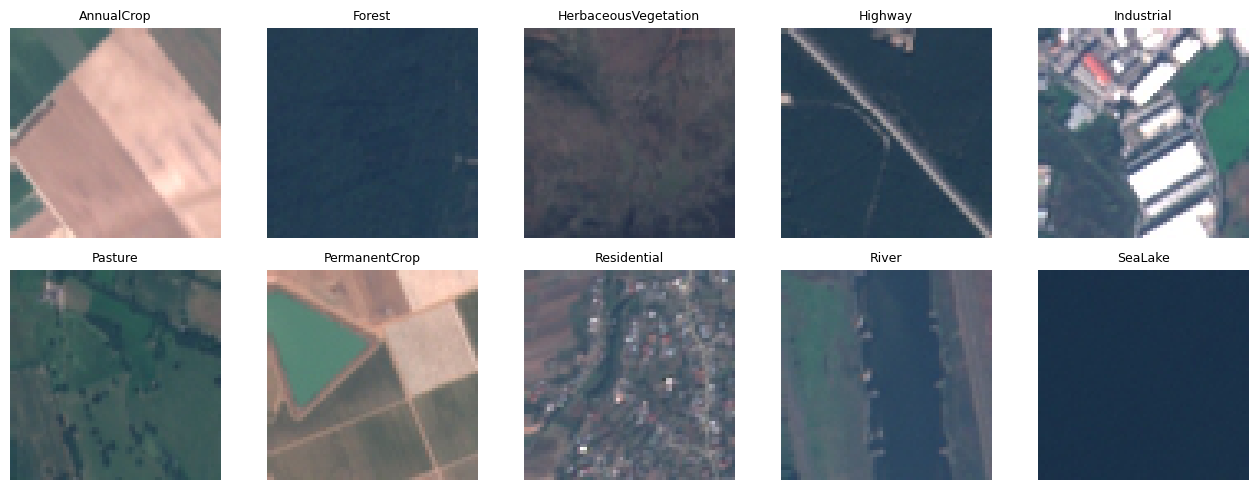

In [15]:
# Visualizamos una imagen por clase del conjunto de entrenamiento, sin aumentos.
preview_dataset = Subset(eval_full, train_indices)
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for label in range(num_classes):
    for index in range(len(train_samples)):
        ruta, image_label = train_samples[index]
        if image_label == label:
            img, _ = preview_dataset[index]
            break
    fila = label // 5
    columna = label % 5
    ax = axes[fila, columna]
    # Deshacemos la normalización para mostrar los colores.
    # Matplotlib espera (alto, ancho, canales), en vez de (canales, alto, ancho).
    ax.imshow(imagen_visible(img))
    ax.set_title(class_names[label], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 1. Arquitectura custom y entrenamiento desde cero
### CNN propia
Usamos cuatro bloques Conv-BatchNorm-LeakyReLU-MaxPool, con 16, 32, 64 y 128 canales.
El pooling global produce un vector de 128 valores y reemplaza la capa densa de
8192 entradas. Dropout regulariza el clasificador. La red se inicializa desde cero.
Los cuatro bloques y BatchNorm conservan la propuesta que discutimos; el loop
de entrenamiento usa Adam con learning rate fijo, sin scheduler.


In [16]:
# Conservamos una clase para registrar los pesos y definir el forward.
class MiCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # CONVOLUCIÓN y BatchNorm: estabiliza las activaciones internas.
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1, bias=False)  # BN agrega el desplazamiento.
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 128, 3, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2)
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)  # Apaga el 30% durante entrenamiento.
        self.classifier = nn.Linear(128, num_classes)

    def forward_features(self, x):
        # FORWARD PROPAGATION: cuatro bloques convolucionales.
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.leaky_relu(x)  # ACTIVACIÓN.
        x = self.pool(x)  # MAX POOLING.
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.conv4(x)
        x = self.bn4(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        # GLOBAL AVERAGE POOLING: un promedio por canal.
        x = self.global_pool(x)
        return torch.flatten(x, 1)  # Representación de 128 dimensiones.

    def forward(self, x):
        x = self.forward_features(x)
        x = self.dropout(x)
        return self.classifier(x)  # Diez logits.


In [17]:
model = MiCNN(num_classes).to(device)
print(model)
parametros_entrenables = 0
for parameter in model.parameters():
    if parameter.requires_grad:
        parametros_entrenables += parameter.numel()
print('Parámetros entrenables:', parametros_entrenables)


MiCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool2d(output_size=1)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=10, b

### Entrenamiento y flujo de gradientes
Registramos loss y accuracy, y elegimos pesos por la menor loss de validación.
Durante tres épocas medimos norma L2 por capa, cociente respecto de la norma del
peso y norma global por iteración. La norma absoluta depende de escala y cantidad
de parámetros; el cociente aporta contexto pero no es el paso relativo de Adam.
Los gráficos son diagnósticos orientativos, sin umbrales universales.


In [18]:
criterion = nn.CrossEntropyLoss()

def entrenar_una_epoca(model, loader, criterion, optimizer, monitorear=False):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    registros = {}
    globales = []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)  # FORWARD PROPAGATION.
        loss = criterion(logits, labels)  # LOSS FUNCTION.
        if not torch.isfinite(loss).item():
            raise RuntimeError('Pérdida no finita')
        loss.backward()  # BACKPROPAGATION.
        if monitorear:
            suma_cuadrados = 0.0
            for name, parameter in model.named_parameters():
                if parameter.grad is None:
                    continue
                grad = parameter.grad.detach()
                norma = grad.norm().item()
                if not np.isfinite(norma):
                    raise RuntimeError('Gradiente no finito en ' + name)
                suma_cuadrados += norma ** 2
                if parameter.ndim > 1:
                    peso = parameter.detach().norm().item()
                    if name not in registros:
                        registros[name] = {'norma': [], 'relativa': []}
                    registros[name]['norma'].append(norma)
                    registros[name]['relativa'].append(norma / max(peso, 1e-12))
            globales.append(suma_cuadrados ** 0.5)
        optimizer.step()  # ACTUALIZACIÓN DE PESOS.
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total, registros, globales

def evaluar(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total


In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
model = MiCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'seconds': []}
gradient_history = []
best_val_loss = float('inf')
best_epoch = 0
best_val_acc = 0.0
for epoch in range(1, EPOCHS + 1):
    inicio = time.time()
    train_loss, train_acc, registros, globales = entrenar_una_epoca(
        model, train_loader, criterion, optimizer, monitorear=epoch <= GRAD_EPOCHS)
    val_loss, val_acc = evaluar(model, val_loader, criterion)
    seconds = time.time() - inicio
    for key, value in [('train_loss', train_loss), ('val_loss', val_loss),
                       ('train_acc', train_acc), ('val_acc', val_acc), ('seconds', seconds)]:
        history[key].append(value)
    if registros:
        gradient_history.append({'epoch': epoch, 'capas': registros, 'global': globales})
    print(f'Época {epoch}/{EPOCHS} | train {train_loss:.4f}, {train_acc:.2f}% '
          f'| val {val_loss:.4f}, {val_acc:.2f}% | {seconds:.1f} s', flush=True)
    if val_loss < best_val_loss:
        best_val_loss, best_val_acc, best_epoch = val_loss, val_acc, epoch
        best_weights = copy.deepcopy(model.state_dict())
model.load_state_dict(best_weights)
model.eval()
print('Mejor época:', best_epoch, '| val accuracy:', best_val_acc)


Época 1/30 | train 0.9109, 68.13% | val 0.8419, 70.72% | 38.6 s
Época 2/30 | train 0.6563, 76.87% | val 0.5814, 80.72% | 37.1 s
Época 3/30 | train 0.5468, 80.87% | val 0.5064, 81.04% | 37.9 s
Época 4/30 | train 0.4969, 82.90% | val 0.4231, 84.65% | 38.4 s
Época 5/30 | train 0.4309, 85.06% | val 0.3845, 86.39% | 43.3 s
Época 6/30 | train 0.3970, 86.37% | val 0.4071, 85.65% | 47.1 s
Época 7/30 | train 0.3646, 87.62% | val 0.5511, 81.07% | 46.6 s
Época 8/30 | train 0.3440, 88.29% | val 0.3090, 88.81% | 44.9 s
Época 9/30 | train 0.3250, 88.99% | val 0.3140, 88.74% | 45.9 s
Época 10/30 | train 0.3173, 89.12% | val 0.2465, 91.72% | 44.2 s
Época 11/30 | train 0.3021, 89.69% | val 0.2479, 91.44% | 43.0 s
Época 12/30 | train 0.2954, 89.92% | val 0.4067, 85.98% | 46.0 s
Época 13/30 | train 0.2807, 90.42% | val 0.3728, 86.59% | 43.7 s
Época 14/30 | train 0.2655, 90.85% | val 0.2743, 90.04% | 43.5 s
Época 15/30 | train 0.2618, 90.94% | val 0.8423, 78.24% | 42.3 s


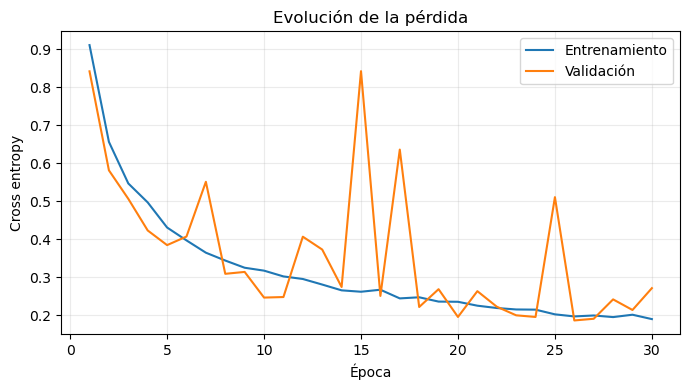

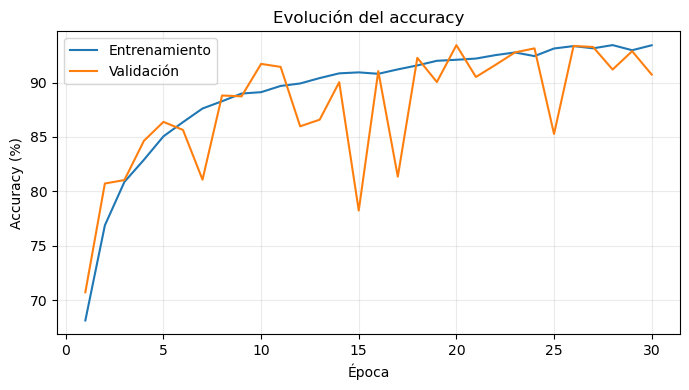

In [ ]:
# CURVAS DE APRENDIZAJE: pérdida y accuracy en entrenamiento y validación.
epochs = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_loss'], label='Entrenamiento')
plt.plot(epochs, history['val_loss'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Cross entropy')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_acc'], label='Entrenamiento')
plt.plot(epochs, history['val_acc'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Accuracy (%)')
plt.title('Evolución del accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


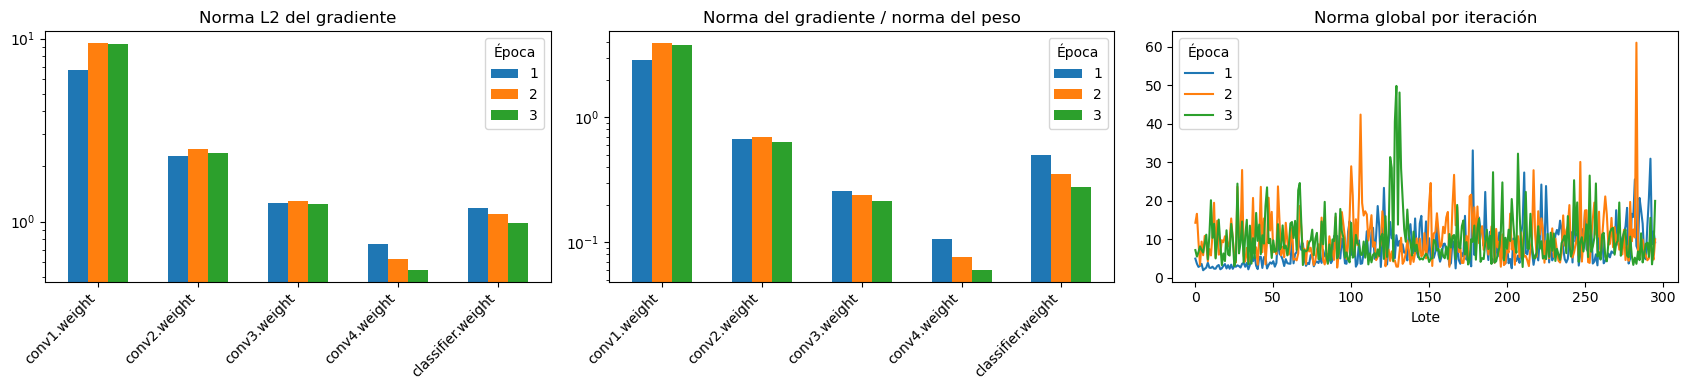

Época 1 | norma global min/media/max: 1.9517605494178483 7.62415268019345 33.0561570481058
Época 2 | norma global min/media/max: 2.6478776225363823 10.123348856042025 61.00173246279071
Época 3 | norma global min/media/max: 2.7936718983288142 9.907243644521406 49.78927858346555


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for record in gradient_history:
    names = list(record['capas'])
    normas, relativas = [], []
    for name in names:
        normas.append(np.mean(record['capas'][name]['norma']))
        relativas.append(np.mean(record['capas'][name]['relativa']))
    posiciones = np.arange(len(names)) + 0.2 * (record['epoch'] - 2)
    axes[0].bar(posiciones, normas, width=0.2, label=str(record['epoch']))
    axes[1].bar(posiciones, relativas, width=0.2, label=str(record['epoch']))
    axes[2].plot(record['global'], label=str(record['epoch']))
for ax in axes[:2]:
    ax.set_xticks(np.arange(len(names)), names, rotation=45, ha='right')
    ax.set_yscale('log')
axes[0].set_title('Norma L2 del gradiente')
axes[1].set_title('Norma del gradiente / norma del peso')
axes[2].set_title('Norma global por iteración')
axes[2].set_xlabel('Lote')
for ax in axes:
    ax.legend(title='Época')
plt.tight_layout()
plt.show()
for record in gradient_history:
    print('Época', record['epoch'], '| norma global min/media/max:',
          np.min(record['global']), np.mean(record['global']), np.max(record['global']))


### Resultados de la CNN y evolución del entrenamiento

La CNN propia tiene **98.970 parámetros entrenables**, frente a 1.055.082 de la
versión anterior. Se reemplazó la gran capa densa por pooling global y se aumentó
la profundidad convolucional. También se incorporaron BatchNorm y dropout, por
lo que esta corrida no permite aislar el efecto de cada cambio por separado.

En 30 épocas con Adam y LR fijo de 0,001, train pasó de **68,13% a 93,43%**.
La mejor época por pérdida de validación fue la **26**, con loss **0,1863** y
accuracy **93,37%**. La última época terminó con **90,74%** en validación, por lo
que conservar los últimos pesos habría descartado un estado mejor.

La pérdida de entrenamiento disminuyó de 0,9109 a 0,1898, pero validación no
mejoró de manera uniforme: por ejemplo, cayó a 78,24% en la época 15 y se recuperó
a 91,06% en la 16. La corrida muestra aprendizaje y una mejora sobre las salidas
anteriores, junto con una variabilidad importante de validación. No corresponde
atribuir toda esa variación a sobreajuste ni afirmar subajuste solo por el número
de convoluciones. Además, train incluye aumentos y dropout, mientras que validación no.

El estado seleccionado obtuvo en las **2.700 imágenes de test** un accuracy de
**94,70%** y un **F1-macro de 0,9452**. Residential tuvo recall de 1,00 al redondear
a dos decimales, mientras que HerbaceousVegetation presentó el menor recall,
**0,86**. Por lo tanto, el rendimiento global alto no elimina dificultades
particulares en las coberturas vegetales.

### Flujo de gradientes

Durante las primeras tres épocas, la norma global media fue **7,62; 10,12 y 9,91**,
y los máximos por iteración fueron **33,06; 61,00 y 49,79**. Hubo picos, pero no
un crecimiento sostenido ni valores no finitos. Las normas de las convoluciones
iniciales fueron mayores que las de la última convolución. Las primeras capas
no quedaron sin señal y la pérdida se redujo durante este período.

En estas tres épocas no observamos evidencia suficiente de desvanecimiento o
explosión. Eso no demuestra que no pueda aparecer un problema más adelante.
La norma absoluta depende de la escala y de la cantidad de parámetros; el cociente
respecto de la norma del peso aporta contexto. Ese cociente **no es la magnitud
relativa de la actualización de Adam**, que además transforma los gradientes.
Un máximo aislado tampoco es un umbral universal de explosión.
La norma global tampoco es el mismo estadístico que el máximo de un elemento
individual del gradiente: no corresponde comparar esos números como si lo fueran.

## 2. Análisis de errores y espacio latente
### Evaluación en test

Evaluamos la CNN con los pesos seleccionados en el punto 1. Reportamos accuracy,
precision, recall y F1 por clase, además de F1-macro para dar el mismo peso a cada
clase. El conjunto de test se utiliza para describir el rendimiento final, sin
ajustar hiperparámetros a partir de sus resultados.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from IPython.display import display, Markdown
from torchvision import models

cnn_custom = model  # Pesos elegidos por validación.
history_custom = copy.deepcopy(history)
best_epoch_custom = best_epoch
best_val_acc_custom = best_val_acc

def predecir(modelo, loader):
    modelo.eval()
    reales = []
    predichas = []
    with torch.no_grad():  # Solo forward propagation.
        for images, labels in loader:
            images = images.to(device)
            logits = modelo(images)
            _, predicted = torch.max(logits, 1)
            reales.extend(labels.tolist())
            predichas.extend(predicted.cpu().tolist())
    return np.array(reales), np.array(predichas)

y_test, pred_custom = predecir(cnn_custom, test_loader)
acc_custom = accuracy_score(y_test, pred_custom)
f1_custom = f1_score(y_test, pred_custom, average='macro', zero_division=0)
print('Accuracy test:', round(acc_custom, 4))
print('F1-macro test:', round(f1_custom, 4))
print(classification_report(y_test, pred_custom, labels=range(num_classes),
                            target_names=class_names, zero_division=0))


Accuracy test: 0.947
F1-macro test: 0.9452
                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.92      0.95       300
              Forest       0.99      0.97      0.98       300
HerbaceousVegetation       0.96      0.86      0.90       300
             Highway       0.95      0.93      0.94       250
          Industrial       0.98      0.96      0.97       250
             Pasture       0.88      0.95      0.92       200
       PermanentCrop       0.87      0.96      0.91       250
         Residential       0.97      1.00      0.98       300
               River       0.90      0.94      0.92       250
             SeaLake       0.98      0.99      0.98       300

            accuracy                           0.95      2700
           macro avg       0.94      0.95      0.95      2700
        weighted avg       0.95      0.95      0.95      2700



### Matriz de confusión

Las filas representan la clase real y las columnas la predicción. La diagonal
contiene los aciertos. Mostramos los conteos y la matriz normalizada por fila,
que permite comparar errores entre clases con distintas cantidades de imágenes.

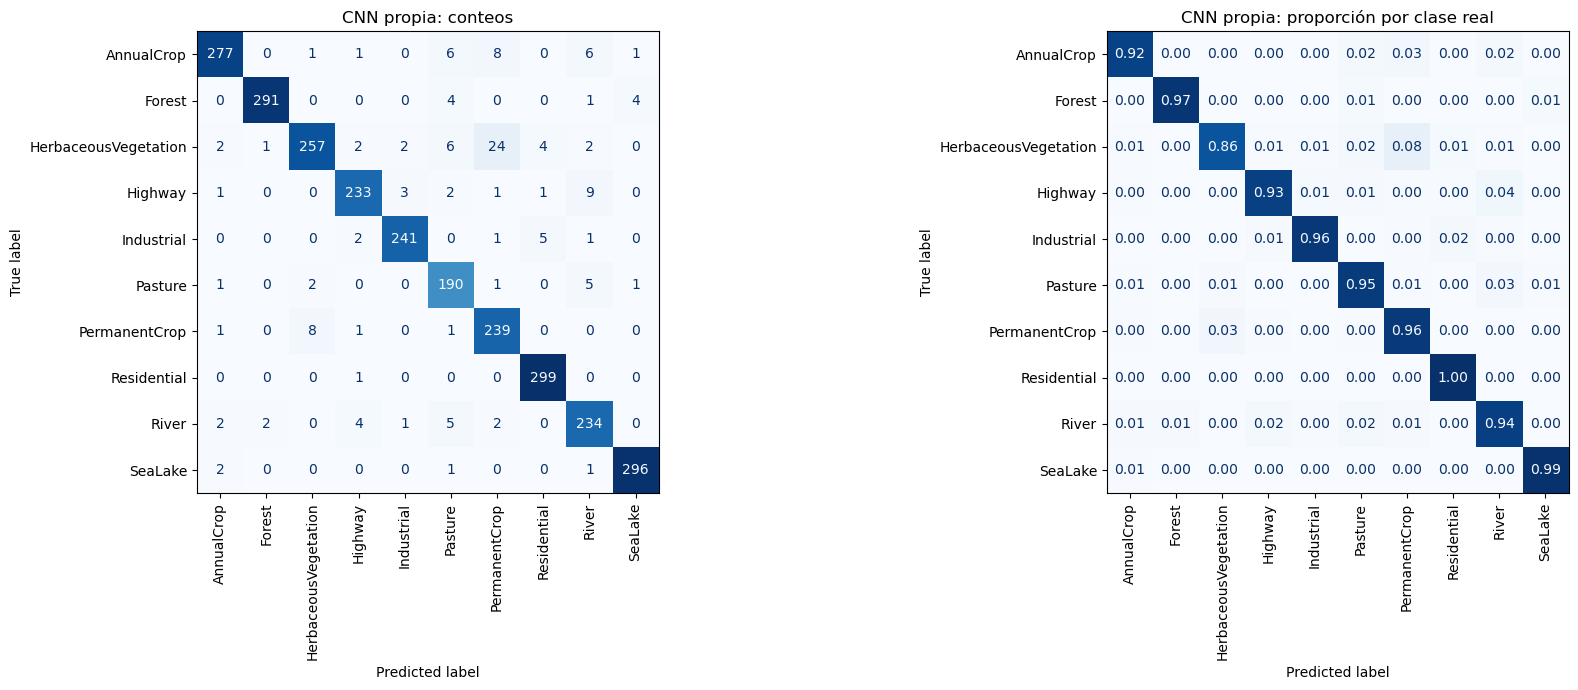

In [ ]:
cm_custom = confusion_matrix(y_test, pred_custom, labels=range(num_classes))
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
ConfusionMatrixDisplay(cm_custom, display_labels=class_names).plot(
    ax=axes[0], cmap='Blues', colorbar=False, xticks_rotation=90
)
cm_normalizada = confusion_matrix(y_test, pred_custom, labels=range(num_classes), normalize='true')
ConfusionMatrixDisplay(cm_normalizada, display_labels=class_names).plot(
    ax=axes[1], cmap='Blues', colorbar=False, xticks_rotation=90, values_format='.2f'
)
axes[0].set_title('CNN propia: conteos')
axes[1].set_title('CNN propia: proporción por clase real')
plt.tight_layout()
plt.show()


### Confusiones más frecuentes
La principal confusión de test fue HerbaceousVegetation ↔ PermanentCrop.
Los gráficos siguientes muestran sus conteos y ejemplos reales, junto con las
otras direcciones de error más frecuentes. El análisis escrito sigue a los resultados.

Las confusiones más frecuentes fueron:

- **HerbaceousVegetation → PermanentCrop**: 24 imágenes (8.0% de la clase real).
- **Highway → River**: 9 imágenes (3.6% de la clase real).
- **PermanentCrop → HerbaceousVegetation**: 8 imágenes (3.2% de la clase real).
- **AnnualCrop → PermanentCrop**: 8 imágenes (2.7% de la clase real).
- **HerbaceousVegetation → Pasture**: 6 imágenes (2.0% de la clase real).


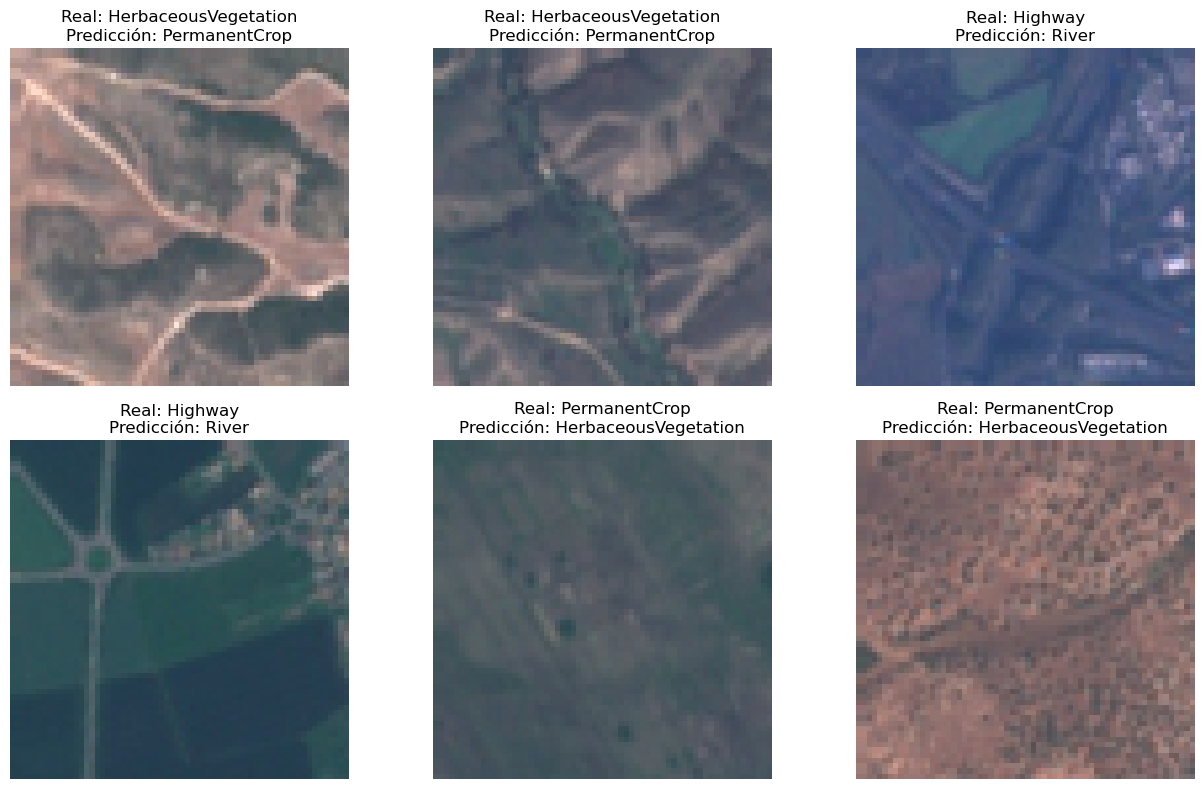

In [ ]:
confusiones = []
for real in range(num_classes):
    for predicha in range(num_classes):
        if real != predicha and cm_custom[real, predicha] > 0:
            confusiones.append((int(cm_custom[real, predicha]), real, predicha))
confusiones.sort(reverse=True)

texto_errores = 'Las confusiones más frecuentes fueron:\n\n'
for count, real, predicha in confusiones[:5]:
    proporcion = count / cm_custom[real].sum()
    texto_errores += (f'- **{class_names[real]} → {class_names[predicha]}**: '
                      f'{count} imágenes ({proporcion:.1%} de la clase real).\n')
if len(confusiones) == 0:
    texto_errores = 'No se observaron errores en este conjunto de test.'
display(Markdown(texto_errores))

ejemplos_error = []
for count, real, predicha in confusiones[:3]:
    encontrados = 0
    for index in range(len(y_test)):
        if y_test[index] == real and pred_custom[index] == predicha:
            ejemplos_error.append(index)
            encontrados += 1
        if encontrados == 2:
            break

if len(ejemplos_error) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for posicion in range(len(ejemplos_error)):
        index = ejemplos_error[posicion]
        image, _ = test_dataset[index]  # Mismo orden que test_loader.
        ax = axes[posicion // 3, posicion % 3]
        ax.imshow(imagen_visible(image))
        ax.set_title('Real: ' + class_names[y_test[index]] +
                     '\nPredicción: ' + class_names[pred_custom[index]])
    plt.tight_layout()
    plt.show()


In [ ]:
# Agrupamos ambos sentidos de cada confusión.
pares = []
for a in range(num_classes):
    for b in range(a + 1, num_classes):
        cantidad = int(cm_custom[a, b] + cm_custom[b, a])
        if cantidad > 0:
            pares.append((cantidad, a, b))
pares.sort(reverse=True)
print('Pares más confundidos, sumando ambos sentidos:')
for cantidad, a, b in pares[:5]:
    print(class_names[a], '/', class_names[b], ':', cantidad,
          '| ida:', cm_custom[a, b], '| vuelta:', cm_custom[b, a])


Pares más confundidos, sumando ambos sentidos:
HerbaceousVegetation / PermanentCrop : 32 | ida: 24 | vuelta: 8
Highway / River : 13 | ida: 9 | vuelta: 4
Pasture / River : 10 | ida: 5 | vuelta: 5
AnnualCrop / PermanentCrop : 9 | ida: 8 | vuelta: 1
HerbaceousVegetation / Pasture : 8 | ida: 6 | vuelta: 2


### Análisis de los errores


El par más confundido fue **HerbaceousVegetation ↔ PermanentCrop**, con **32 errores**:
24 de HerbaceousVegetation hacia PermanentCrop y ocho en sentido contrario.
En los ejemplos de HerbaceousVegetation se observan manchas de vegetación y suelo
separadas por caminos; no hay filas de cultivo nítidas. Uno de los recortes de
PermanentCrop es una superficie verde bastante homogénea y otro muestra una trama
de plantación que se ve tenue a esta resolución. La distinción exige reconocer
la organización espacial, además del color. Esto justifica la similitud visual
del par, sin probar qué característica causó cada decisión interna de la red.

**Highway ↔ River** sumó **13 errores**: nueve carreteras predichas como río y cuatro
ríos predichos como carretera. Los dos ejemplos mostrados de Highway contienen
trazos estrechos y cruces sobre fondos oscuros o verdes. Comparten el carácter
lineal con los ríos, pero los cruces y la regularidad de los caminos son diferencias
que el modelo no aprovechó en esos casos. Los recortes tienen solo 64 × 64 píxeles,
por lo que esas diferencias ocupan pocos píxeles.

También aparecen **Pasture ↔ River** con diez errores, **AnnualCrop ↔ PermanentCrop**
con nueve y **HerbaceousVegetation ↔ Pasture** con ocho. Los conteos por sí solos
no permiten asignar una explicación visual a todos ellos: el análisis detallado
anterior se limita a los pares para los que se muestran recortes concretos.

### Espacio latente: PCA y t-SNE
Extraemos las 128 características anteriores al clasificador. PCA se ajusta con
train y proyecta test. t-SNE representa una muestra reproducible de test, con las
etiquetas usadas solo para colorear. Ambos métodos están incluidos en el enunciado.
PCA permite conocer cuánta varianza conserva la proyección. Los ejes y distancias
globales de t-SNE no tienen una interpretación métrica fiable. La lectura visual
debe contrastarse con las confusiones observadas, sin presentarla como prueba de
clusters naturales. 


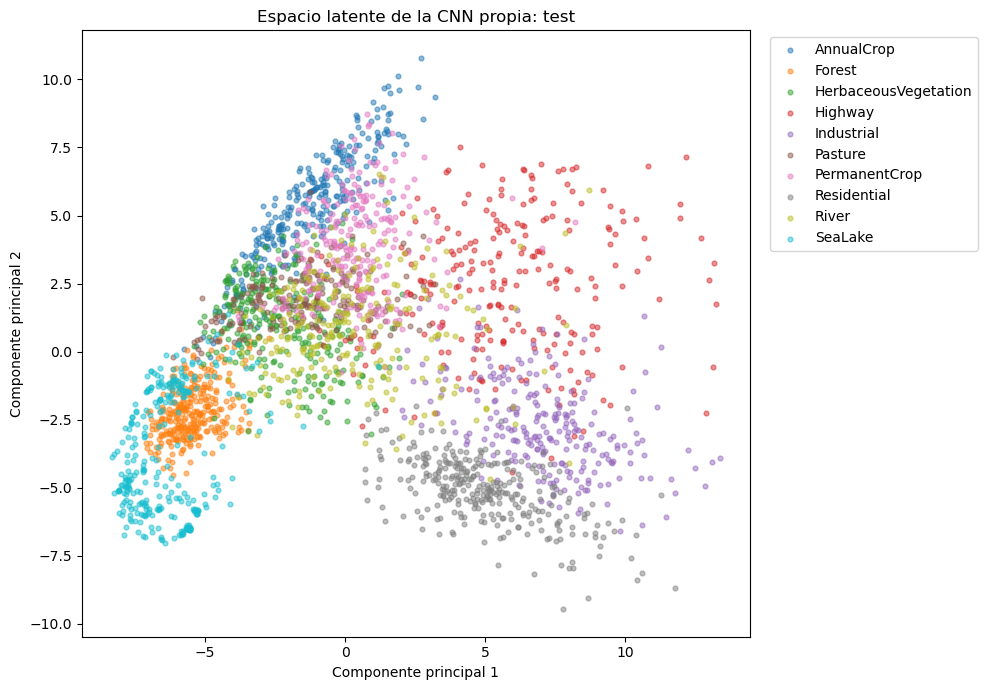

Las dos componentes conservan **45.7%** de la varianza de las características de entrenamiento. Para interpretar los grupos debemos considerar esa pérdida de información.

In [ ]:
def extraer_features(modelo, loader):
    modelo.eval()
    features = []
    etiquetas = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            salida = modelo.forward_features(images)  # Antes del clasificador.
            features.append(salida.cpu().numpy())
            etiquetas.extend(labels.tolist())
    return np.concatenate(features, axis=0), np.array(etiquetas)

train_latente_dataset = Subset(eval_full, train_indices)
train_latente_loader = DataLoader(train_latente_dataset, batch_size=BATCH_SIZE,
                                  shuffle=False, num_workers=NUM_WORKERS)
features_train, labels_latentes_train = extraer_features(cnn_custom, train_latente_loader)
features_test, labels_latentes_test = extraer_features(cnn_custom, test_loader)

pca = PCA(n_components=2, svd_solver='full')
pca.fit(features_train)  # Sin utilizar test para ajustar la proyección.
proyeccion_test = pca.transform(features_test)
varianza_pca = pca.explained_variance_ratio_.sum()

plt.figure(figsize=(10, 7))
for label in range(num_classes):
    seleccion = labels_latentes_test == label
    plt.scatter(proyeccion_test[seleccion, 0], proyeccion_test[seleccion, 1],
                s=12, alpha=0.5, label=class_names[label])
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Espacio latente de la CNN propia: test')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
display(Markdown(f'Las dos componentes conservan **{varianza_pca:.1%}** de la '
                 'varianza de las características de entrenamiento. '
                 'Para interpretar los grupos debemos considerar esa pérdida de información.'))


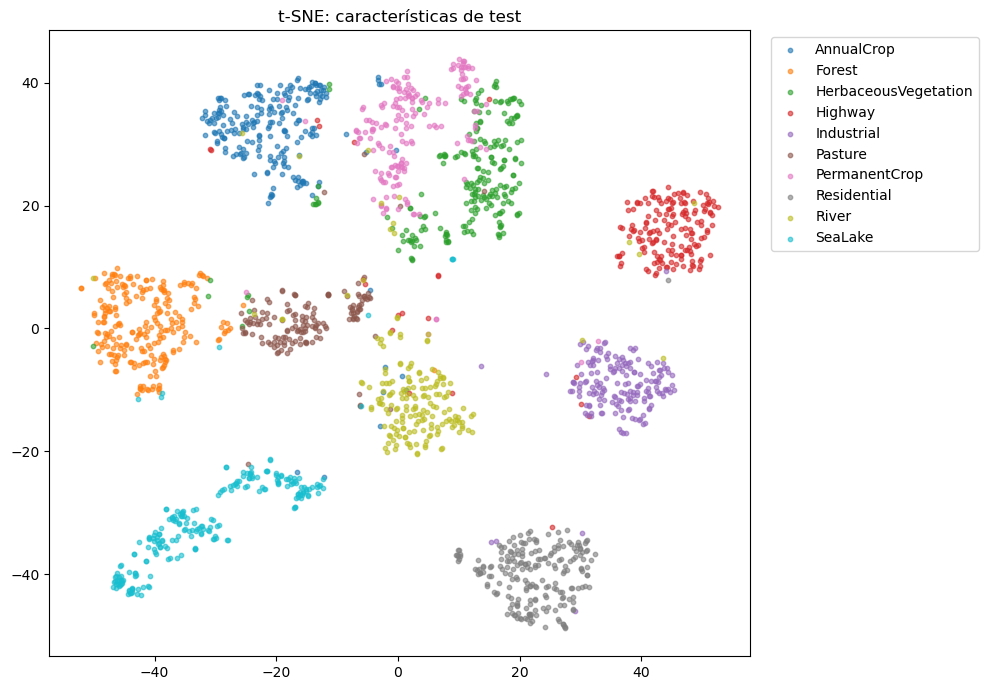

In [ ]:
from sklearn.manifold import TSNE
muestreo = np.random.default_rng(SEED)
indices_latentes = muestreo.choice(len(features_test), min(2000, len(features_test)), replace=False)
features_muestra = features_test[indices_latentes]
labels_muestra = labels_latentes_test[indices_latentes]
tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED)
proyeccion_tsne = tsne.fit_transform(features_muestra)
plt.figure(figsize=(10, 7))
for label in range(num_classes):
    seleccion = labels_muestra == label
    plt.scatter(proyeccion_tsne[seleccion, 0], proyeccion_tsne[seleccion, 1],
                s=10, alpha=0.6, label=class_names[label])
plt.title('t-SNE: características de test')
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


### Análisis del espacio latente


PCA conserva **45,7%** de la varianza de train con dos componentes. Se distinguen
regiones dominadas por Forest y SeaLake hacia la izquierda, AnnualCrop en la parte
superior y Residential e Industrial hacia la derecha. HerbaceousVegetation,
PermanentCrop y Pasture se mezclan en la zona central. La superposición no demuestra
que las clases sean inseparables en las 128 dimensiones: la proyección descarta
el 54,3% de la varianza.

En la proyección t-SNE de 2.000 imágenes aparecen grupos mayormente dominados por
una clase, especialmente Residential, Industrial y Highway. HerbaceousVegetation
y PermanentCrop quedan próximas y muestran puntos mezclados, en consonancia con
la confusión principal del clasificador. SeaLake forma más de una nube, por lo
que ni siquiera una misma clase tiene que aparecer como un único grupo compacto.

Estas visualizaciones muestran que la representación aprendida contiene información
útil para distinguir las clases antes de la capa final. No prueban clusters naturales
ni permiten interpretar las distancias globales de t-SNE como distancias entre
tipos de terreno. 

## 3. Transfer Learning
### ResNet18: ajuste de las últimas capas
Cargamos los pesos de ImageNet, congelamos las capas iniciales y ajustamos `layer4`
y `fc`, con learning rates fijos de 0,0001 y 0,001. ResNet18 está admitida en el
enunciado. Las capas congeladas quedan en eval para conservar sus estadísticas
de BatchNorm. El loop conserva la estructura de la práctica 17.
Ambos modelos usan el mismo pipeline y un máximo de 30 épocas, sin scheduler.
La comparación sigue combinando efectos de arquitectura y preentrenamiento.


In [ ]:
EPOCHS_TL = EPOCHS
LR_TL = 1e-3
train_loader_tl = train_loader
val_loader_tl = val_loader
test_loader_tl = test_loader


In [ ]:
torch.manual_seed(SEED)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_tl = models.resnet18(weights=weights)
for parameter in model_tl.parameters():
    parameter.requires_grad = False  # CONGELAMIENTO.
for parameter in model_tl.layer4.parameters():
    parameter.requires_grad = True  # FINE-TUNING: última etapa residual.
model_tl.fc = nn.Linear(model_tl.fc.in_features, num_classes)
model_tl = model_tl.to(device)
optimizer_tl = torch.optim.Adam([
    {'params': model_tl.layer4.parameters(), 'lr': 1e-4},
    {'params': model_tl.fc.parameters(), 'lr': 1e-3},
])
print('Entrenables:', sum(p.numel() for p in model_tl.parameters() if p.requires_grad))


Entrenables: 8398858


### Fine-tuning
En cada época dejamos la red en eval y activamos train solo en `layer4` y `fc`.
Esto permite ajustar las últimas convoluciones sin cambiar las estadísticas
BatchNorm de las capas congeladas. El mejor estado completo se elige por validación.


In [ ]:
def entrenar_una_epoca_tl(modelo, loader, criterion, optimizer):
    modelo.eval()  # Congeladas: pesos y estadísticas fijos.
    modelo.layer4.train()
    modelo.fc.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = modelo(images)  # FORWARD PROPAGATION.
        loss = criterion(logits, labels)
        loss.backward()  # BACKPROPAGATION en layer4 y fc.
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total

history_tl = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'seconds': []}
best_val_loss_tl = float('inf')
best_epoch_tl = 0
best_val_acc_tl = 0.0
for epoch in range(1, EPOCHS_TL + 1):
    inicio = time.time()
    train_loss, train_acc = entrenar_una_epoca_tl(model_tl, train_loader_tl, criterion, optimizer_tl)
    val_loss, val_acc = evaluar(model_tl, val_loader_tl, criterion)
    seconds = time.time() - inicio
    for key, value in [('train_loss', train_loss), ('val_loss', val_loss),
                       ('train_acc', train_acc), ('val_acc', val_acc), ('seconds', seconds)]:
        history_tl[key].append(value)
    print(f'ResNet18 {epoch}/{EPOCHS_TL} | train {train_loss:.4f}, {train_acc:.2f}% '
          f'| val {val_loss:.4f}, {val_acc:.2f}% | {seconds:.1f} s', flush=True)
    if val_loss < best_val_loss_tl:
        best_val_loss_tl, best_val_acc_tl, best_epoch_tl = val_loss, val_acc, epoch
        best_tl_weights = copy.deepcopy(model_tl.state_dict())
model_tl.load_state_dict(best_tl_weights)
model_tl.eval()
print('Mejor época ResNet18:', best_epoch_tl)


ResNet18 1/30 | train 0.3666, 87.96% | val 0.1939, 93.70% | 147.1 s
ResNet18 2/30 | train 0.1914, 93.44% | val 0.1719, 94.20% | 133.4 s
ResNet18 3/30 | train 0.1485, 94.95% | val 0.1585, 94.85% | 130.8 s
ResNet18 4/30 | train 0.1262, 95.65% | val 0.1390, 95.19% | 128.6 s
ResNet18 5/30 | train 0.1179, 95.95% | val 0.1550, 94.93% | 168.5 s
ResNet18 6/30 | train 0.1027, 96.52% | val 0.1398, 95.11% | 161.0 s
ResNet18 7/30 | train 0.0890, 96.83% | val 0.1567, 94.87% | 143.0 s
ResNet18 8/30 | train 0.0798, 97.19% | val 0.1454, 95.41% | 157.9 s
ResNet18 9/30 | train 0.0762, 97.28% | val 0.1485, 95.41% | 151.8 s
ResNet18 10/30 | train 0.0752, 97.26% | val 0.1487, 95.43% | 153.7 s
ResNet18 11/30 | train 0.0679, 97.79% | val 0.1496, 95.09% | 148.7 s
ResNet18 12/30 | train 0.0575, 97.86% | val 0.1528, 95.31% | 148.3 s
ResNet18 13/30 | train 0.0614, 97.87% | val 0.1522, 95.65% | 150.2 s
ResNet18 14/30 | train 0.0509, 98.25% | val 0.1456, 95.81% | 152.6 s
ResNet18 15/30 | train 0.0559, 98.17% | val

### Velocidad de convergencia y tiempo
Ambos modelos usan los mismos CSV, lotes de 64, imágenes de 64 × 64, CPU y 30 épocas.
El tiempo incluye carga de datos, entrenamiento y validación. Excluye descarga de
pesos y análisis posterior. Las primeras tres épocas de la CNN incluyen monitoreo
de gradientes; reportamos también su media de tiempo sin esas épocas.


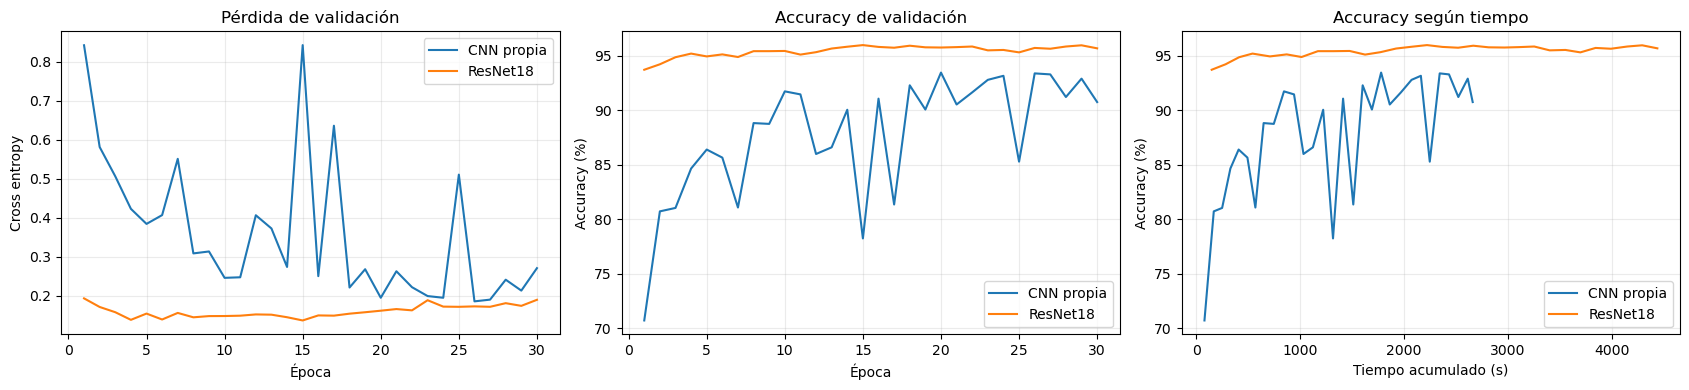

Comparación con el mismo número de épocas:
Época 1 | CNN: 70.72 % | ResNet18: 93.7 %
Época 2 | CNN: 80.72 % | ResNet18: 94.2 %
Época 3 | CNN: 81.04 % | ResNet18: 94.85 %
Época 4 | CNN: 84.65 % | ResNet18: 95.19 %
Época 5 | CNN: 86.39 % | ResNet18: 94.93 %
Época 6 | CNN: 85.65 % | ResNet18: 95.11 %
Época 7 | CNN: 81.07 % | ResNet18: 94.87 %
Época 8 | CNN: 88.81 % | ResNet18: 95.41 %
Época 9 | CNN: 88.74 % | ResNet18: 95.41 %
Época 10 | CNN: 91.72 % | ResNet18: 95.43 %
Época 11 | CNN: 91.44 % | ResNet18: 95.09 %
Época 12 | CNN: 85.98 % | ResNet18: 95.31 %
Época 13 | CNN: 86.59 % | ResNet18: 95.65 %
Época 14 | CNN: 90.04 % | ResNet18: 95.81 %
Época 15 | CNN: 78.24 % | ResNet18: 95.96 %
Época 16 | CNN: 91.06 % | ResNet18: 95.8 %
Época 17 | CNN: 81.35 % | ResNet18: 95.72 %
Época 18 | CNN: 92.28 % | ResNet18: 95.91 %
Época 19 | CNN: 90.06 % | ResNet18: 95.76 %
Época 20 | CNN: 93.44 % | ResNet18: 95.74 %
Época 21 | CNN: 90.52 % | ResNet18: 95.78 %
Época 22 | CNN: 91.63 % | ResNet18: 95.83 %
É

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, historial in [('CNN propia', history_custom), ('ResNet18', history_tl)]:
    epochs_modelo = range(1, len(historial['val_loss']) + 1)
    tiempo_acumulado = np.cumsum(historial['seconds'])
    axes[0].plot(epochs_modelo, historial['val_loss'], label=name)
    axes[1].plot(epochs_modelo, historial['val_acc'], label=name)
    axes[2].plot(tiempo_acumulado, historial['val_acc'], label=name)
axes[0].set_title('Pérdida de validación')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Cross entropy')
axes[1].set_title('Accuracy de validación')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy (%)')
axes[2].set_title('Accuracy según tiempo')
axes[2].set_xlabel('Tiempo acumulado (s)')
axes[2].set_ylabel('Accuracy (%)')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

epocas_comunes = min(len(history_custom['val_acc']), len(history_tl['val_acc']))
print('Comparación con el mismo número de épocas:')
for epoch in range(epocas_comunes):
    print('Época', epoch + 1, '| CNN:', round(history_custom['val_acc'][epoch], 2),
          '% | ResNet18:', round(history_tl['val_acc'][epoch], 2), '%')


### Rendimiento final en test

Los dos modelos llegan a esta comparación con sus pesos ya elegidos por validación.
Evaluamos ResNet18 sobre las mismas imágenes de test y reunimos las métricas de ambos.
La comparación es descriptiva; si se realizan nuevos ajustes, deben decidirse
con entrenamiento y validación, no buscando mejorar el resultado de test.

                      precision    recall  f1-score   support

          AnnualCrop       0.95      0.97      0.96       300
              Forest       0.98      0.99      0.99       300
HerbaceousVegetation       0.96      0.95      0.96       300
             Highway       0.94      0.89      0.91       250
          Industrial       0.96      0.98      0.97       250
             Pasture       0.94      0.96      0.95       200
       PermanentCrop       0.95      0.93      0.94       250
         Residential       0.99      0.99      0.99       300
               River       0.93      0.96      0.94       250
             SeaLake       1.00      0.99      1.00       300

            accuracy                           0.96      2700
           macro avg       0.96      0.96      0.96      2700
        weighted avg       0.96      0.96      0.96      2700



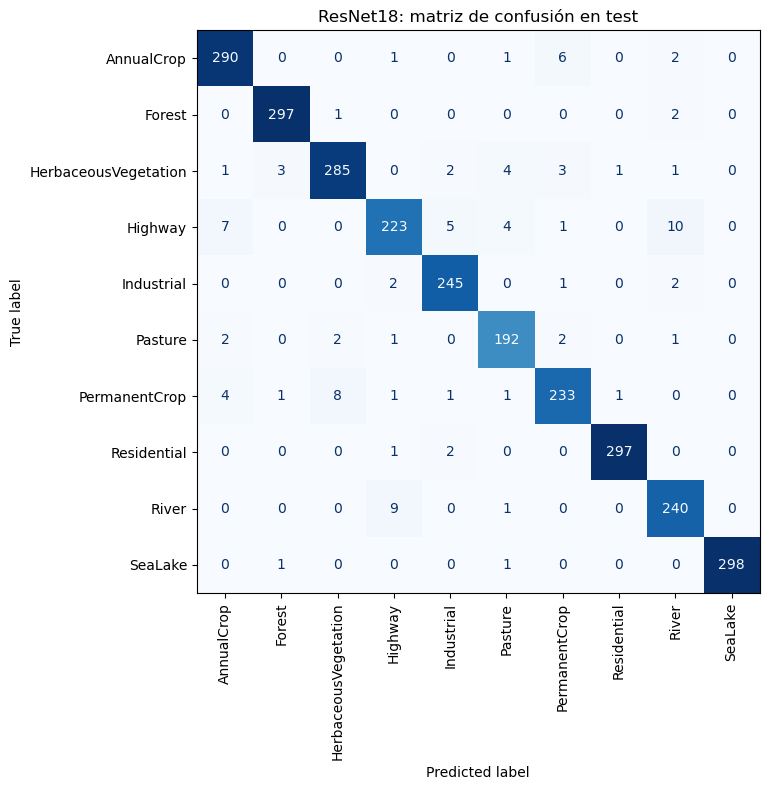

| Modelo | Accuracy test | F1-macro test | Mejor época (val loss) | Val accuracy de esa época | Segundos/época |
|---|---:|---:|---:|---:|---:|
| CNN propia | 0.9470 | 0.9452 | 26 | 93.37% | 88.70 |
| ResNet18 | 0.9630 | 0.9611 | 15 | 95.96% | 147.99 |


In [ ]:
y_test_tl, pred_tl = predecir(model_tl, test_loader_tl)
assert np.array_equal(y_test, y_test_tl)
acc_tl = accuracy_score(y_test_tl, pred_tl)
f1_tl = f1_score(y_test_tl, pred_tl, average='macro', zero_division=0)
print(classification_report(y_test_tl, pred_tl, labels=range(num_classes),
                            target_names=class_names, zero_division=0))

cm_tl = confusion_matrix(y_test_tl, pred_tl, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_tl, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90
)
ax.set_title('ResNet18: matriz de confusión en test')
plt.tight_layout()
plt.show()

tiempo_custom = float(np.mean(history_custom['seconds']))
tiempo_tl = float(np.mean(history_tl['seconds']))
tabla = '| Modelo | Accuracy test | F1-macro test | Mejor época (val loss) | Val accuracy de esa época | Segundos/época |\n'
tabla += '|---|---:|---:|---:|---:|---:|\n'
tabla += (f'| CNN propia | {acc_custom:.4f} | {f1_custom:.4f} | {best_epoch_custom} | '
          f'{best_val_acc_custom:.2f}% | {tiempo_custom:.2f} |\n')
tabla += (f'| ResNet18 | {acc_tl:.4f} | {f1_tl:.4f} | {best_epoch_tl} | '
          f'{best_val_acc_tl:.2f}% | {tiempo_tl:.2f} |\n')
display(Markdown(tabla))


## Conclusión

Reunimos el rendimiento de ambos enfoques y el costo de entrenamiento.
La conclusión siguiente se completa con los resultados de la ejecución, siguiendo
el formato del TP2: métricas obtenidas, comparación y límites de la interpretación.

In [ ]:
conclusion = (f'La CNN propia obtuvo accuracy **{acc_custom:.4f}** y F1-macro '
              f'**{f1_custom:.4f}** en test. ResNet18 obtuvo accuracy **{acc_tl:.4f}** '
              f'y F1-macro **{f1_tl:.4f}**. Las mejores épocas por loss de validación '
              f'fueron {best_epoch_custom} y {best_epoch_tl}.\n\n'
              f'El tiempo medio por época fue {tiempo_custom:.1f} s y {tiempo_tl:.1f} s. '
              f'En la CNN, sin las tres épocas monitoreadas, fue '
              f'{np.mean(history_custom["seconds"][GRAD_EPOCHS:]):.1f} s. '
              'La comparación controla resolución y pipeline, pero combina cambios '
              'de arquitectura y preentrenamiento.\n\n'
              f'PCA conserva {varianza_pca:.1%} de varianza en dos dimensiones. '
              'La proyección t-SNE complementa la visualización, pero '
              'no conserva de forma fiable las distancias globales y '
              'no garantiza clusters separados. Los errores observados y el análisis '
              'visual se desarrollan en el punto 2.')
display(Markdown(conclusion))


La CNN propia obtuvo accuracy **0.9470** y F1-macro **0.9452** en test. ResNet18 obtuvo accuracy **0.9630** y F1-macro **0.9611**. Las mejores épocas por loss de validación fueron 26 y 15.

El tiempo medio por época fue 88.7 s y 148.0 s. En la CNN, sin las tres épocas monitoreadas, fue 89.4 s. La comparación controla resolución y pipeline, pero combina cambios de arquitectura y preentrenamiento.

PCA conserva 45.7% de varianza en dos dimensiones. La proyección t-SNE complementa la visualización, pero no conserva de forma fiable las distancias globales y no garantiza clusters separados. Los errores observados y el análisis visual se desarrollan en el punto 2.

### Análisis de transferencia y conclusión

ResNet18 ajustó **8.398.858 parámetros** de `layer4` y `fc`; las capas anteriores
conservaron sus pesos y estadísticas de BatchNorm. En su primera época alcanzó
**93.70%** en validación, frente al **70,72%** inicial de la CNN propia.
En tres épocas llegó a **94.85%**, mientras la CNN registró **81,04%**.
Esta es una ventaja de convergencia observada con el pipeline acordado, no una
prueba que aísle el efecto del preentrenamiento de la arquitectura.

La época elegida fue la **15**, con loss de validación **0.1374**
y accuracy **95.96%**. Train pasó de **87.96% a 99.14%**,
pero la última validación fue **95.67%**. Se restauró el estado de menor
pérdida en lugar de usar automáticamente los últimos pesos. Las mejoras de train
no se tradujeron de manera uniforme en menor pérdida de validación.

En test, ResNet18 obtuvo **96.30% de accuracy** y **0.9611 de F1-macro**.
La CNN propia obtuvo **94,70%** y **0,9452**, respectivamente.
La diferencia descriptiva fue de aproximadamente **1.6 puntos porcentuales** de accuracy
y **0.016** de F1-macro. Es el resultado de una partición y una semilla;
no se afirma que la diferencia esté garantizada en otras particiones.

La mejora se concentra especialmente en HerbaceousVegetation: su recall pasó de
**0,86 a 0,95**. Sus predicciones erróneas como PermanentCrop bajaron de **24 a tres**;
el sentido contrario conservó ocho casos. El par pasó de **32 a 11 errores**.
En cambio, Highway redujo su recall de **0,93 a 0,89**, y Highway ↔ River aumentó
de **13 a 19 errores**. El mejor resultado global no significó una mejora en cada clase.

El tiempo medio por época de ResNet18 fue **147.99 s**, con tiempos entre
**128.6 y 168.5 s**, frente a **88,7 s** de la CNN. Por tanto,
su arranque fue más rápido en términos de aprendizaje por época, pero cada época
fue más costosa en esta CPU. Los tiempos incluyen lectura de datos, entrenamiento
y validación. No incluyen descargar pesos ni el entrenamiento original de ImageNet.
La variabilidad de los tiempos impide tratar la razón entre medias como una
constante independiente de la carga del equipo.

Ambos enfoques usaron 64 × 64, las mismas particiones, normalización, aumentos,
lotes y 30 épocas, con tasas de aprendizaje fijas. Esto corrige la comparación
anterior entre 64 y 224 píxeles, aunque no separa el efecto de arquitectura,
capacidad y preentrenamiento. El presupuesto iguala épocas, no tiempo de cómputo.
Las rutas de los CSV no se superponen, pero sin coordenadas no se pudo comprobar
independencia geográfica entre recortes.

Test no se utilizó para elegir épocas o tasas. La conclusión se apoya en las
métricas ejecutadas, las matrices de confusión y
los ejemplos de errores mostrados, con las limitaciones señaladas.

En esta ejecución, ResNet18 obtuvo el mayor F1-macro de test, a cambio de un mayor costo por época. La CNN propia fue más económica de entrenar por época y tuvo muchos menos parámetros. El resultado favorece al fine-tuning en métricas bajo este protocolo, sin afirmar que sea superior en cualquier contexto.